In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

base_path = "/content/drive/MyDrive/Employee-Attrition-XAI"

folders = [
    "datasets",
    "notebooks",
    "models",
    "reports",
    "images"
]

for folder in folders:
    os.makedirs(os.path.join(base_path, folder), exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
dataset_path = "/content/drive/MyDrive/Employee-Attrition-XAI/datasets/HR-Employee-Attrition.csv"

df = pd.read_csv(dataset_path)
df.head()
df.shape
df.columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [ ]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


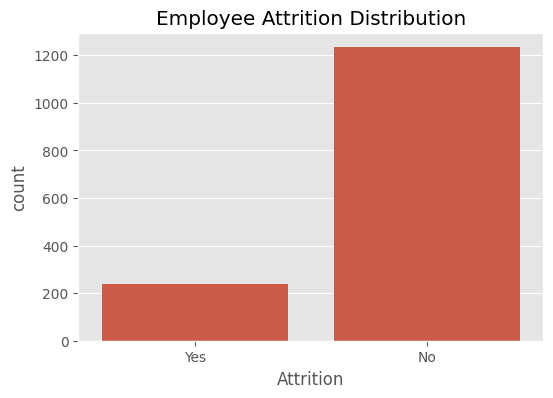

In [ ]:
df["Attrition"].value_counts()
attrition_percent = df["Attrition"].value_counts(normalize=True) * 100
print(attrition_percent)
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Distribution")
plt.show()

### Observation

# - Most employees stayed in the company.
# - Only a small percentage left.
# - The dataset is imbalanced.

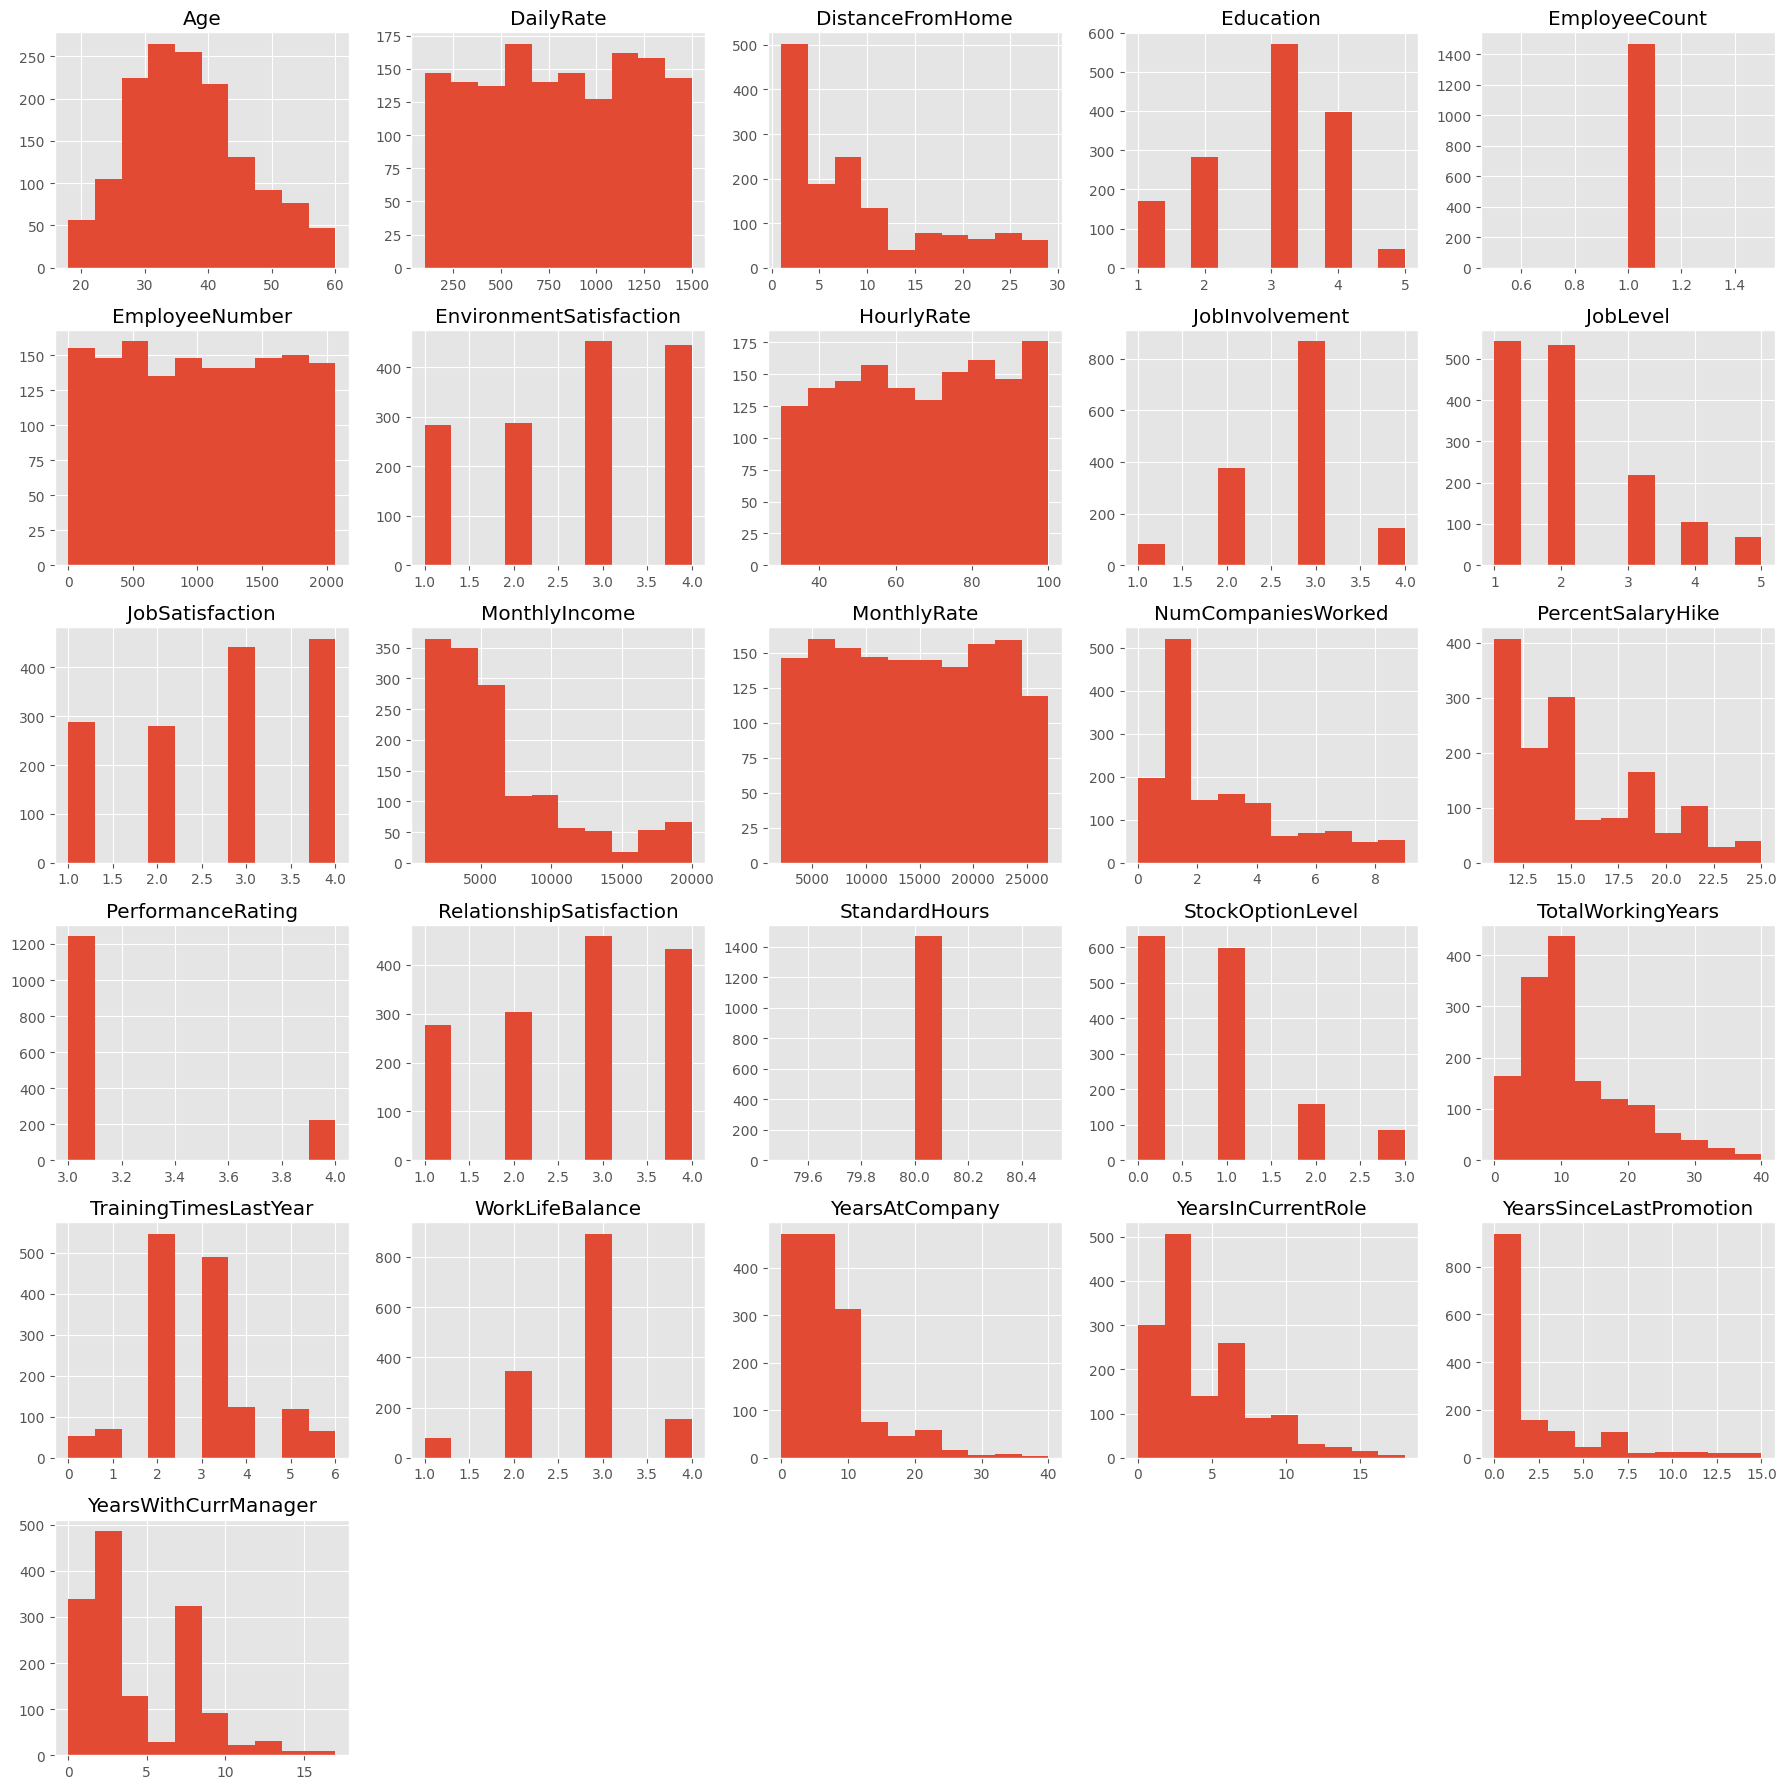

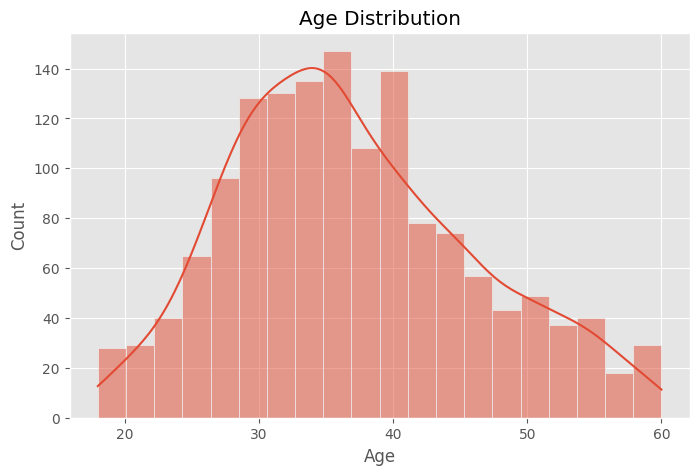

In [ ]:
df.hist(figsize=(18,18))

plt.tight_layout()

plt.show()

plt.figure(figsize=(8,5))

sns.histplot(df["Age"], bins=20, kde=True)

plt.title("Age Distribution")

plt.show()

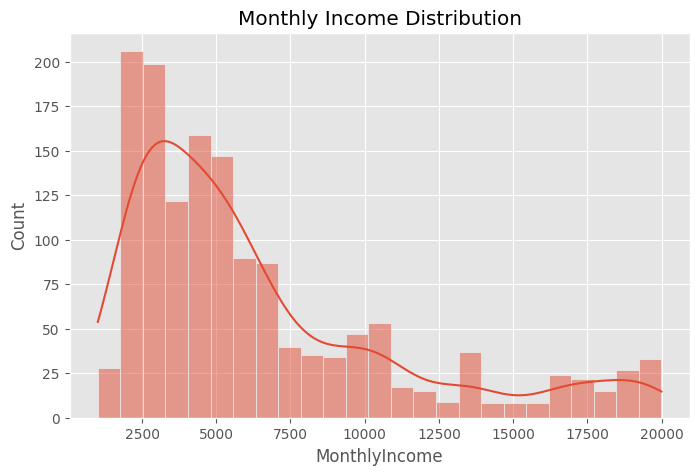

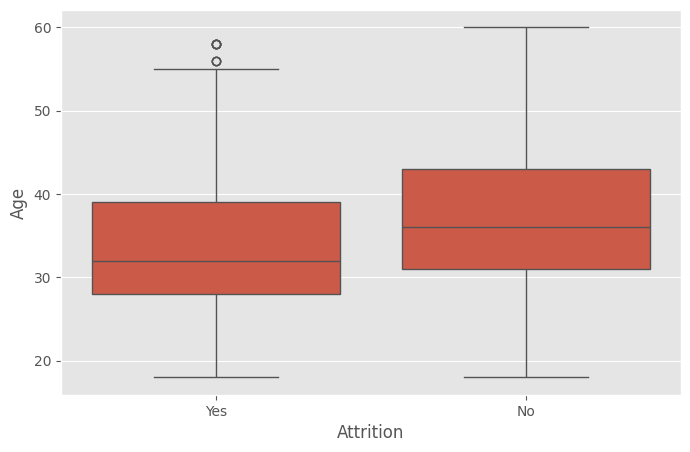

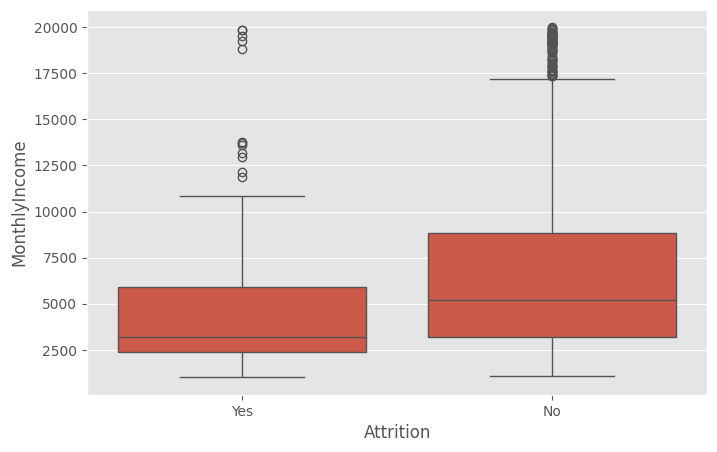

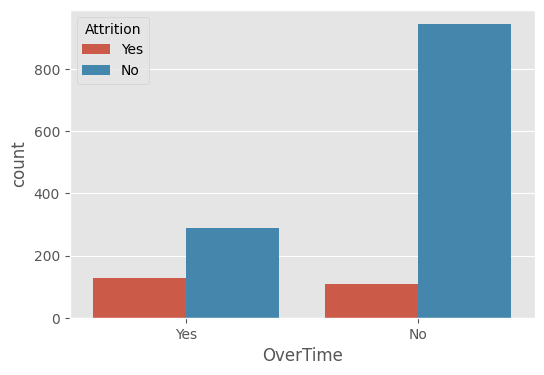

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["MonthlyIncome"], bins=25, kde=True)

plt.title("Monthly Income Distribution")

plt.show()

plt.figure(figsize=(8,5))

sns.boxplot(x="Attrition", y="Age", data=df)

plt.show()

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Attrition",
    y="MonthlyIncome"
)

plt.show()

plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="OverTime",
    hue="Attrition"
)

plt.show()

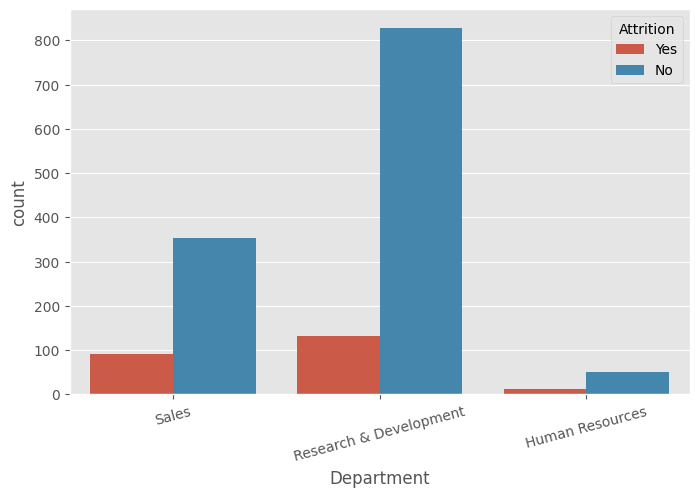

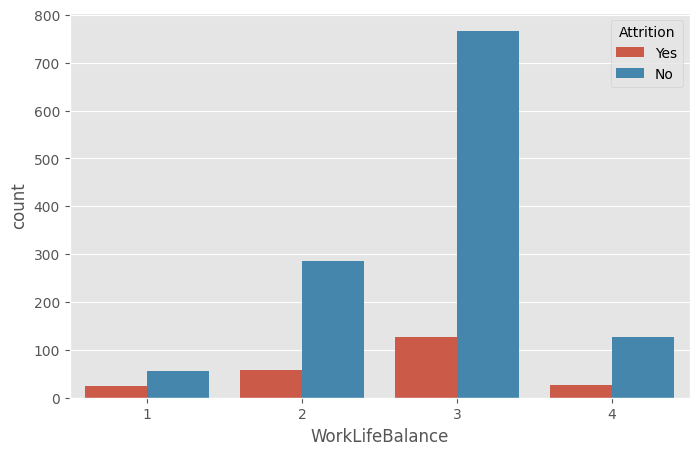

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Department",
    hue="Attrition"
)

plt.xticks(rotation=15)

plt.show()
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="WorkLifeBalance",
    hue="Attrition"
)

plt.show()


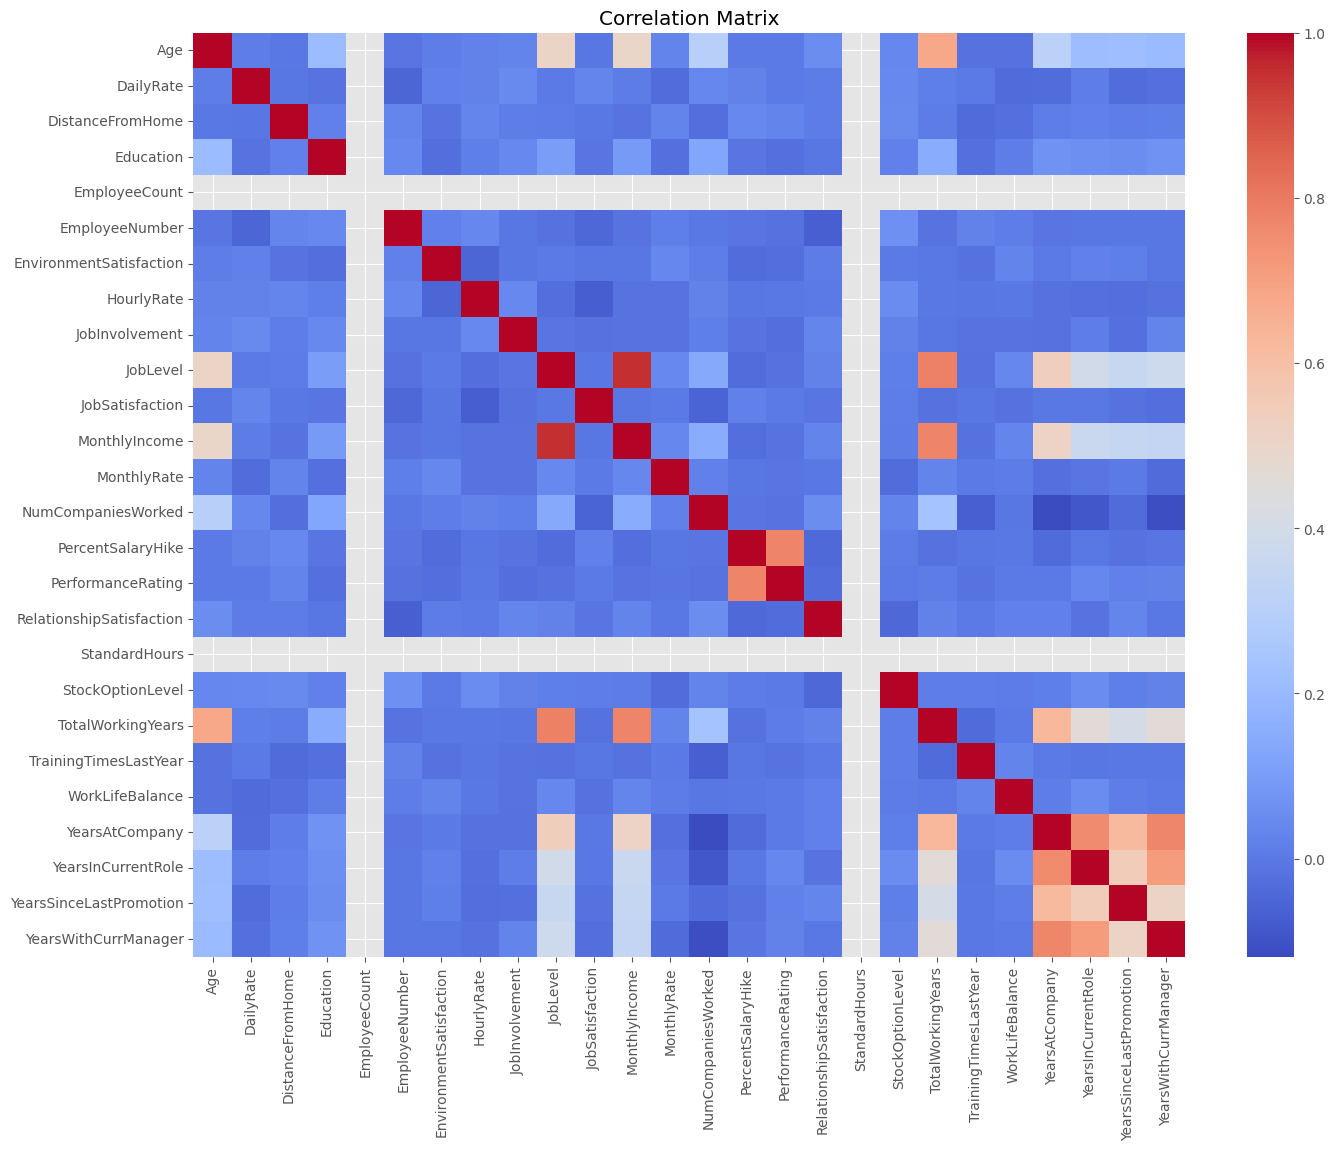

In [ ]:
plt.figure(figsize=(16,12))

corr = df.corr(numeric_only=True)

sns.heatmap(corr, cmap="coolwarm")

plt.title("Correlation Matrix")

plt.show()

# A correlation matrix is a table that shows how strongly two numerical features are related.

# For example:

# Does Age increase with Monthly Income?
# Does YearsAtCompany increase with TotalWorkingYears?
# Does JobLevel increase with MonthlyIncome?

# The correlation matrix answers these questions using the Pearson Correlation Coefficient.

# In the IBM HR Dataset

# You may notice strong correlations such a
s:

# Feature 1	Feature 2	Reason
# JobLevel	MonthlyIncome	Higher-level jobs usually pay more
# TotalWorkingYears	MonthlyIncome	More experience often leads to higher income
# YearsAtCompany	YearsWithCurrManager	Employees who stay longer often remain with the same manager
# TotalWorkingYears	Age	Older employees generally have more work experience

# These relationships make business sense.